# Customer Revenue Intelligence Platform
## 01 — Data Quality and Preprocessing

**Dataset:** UCI Online Retail  
**Purpose:** Understand the source data, investigate quality issues, explain preprocessing decisions, and validate the existing Python pipeline.

### Business objective
Prepare a reliable transaction-level dataset for customer, product, and revenue analysis without silently deleting records or treating every unusual transaction as an error.

### Important principles
- The raw Excel file is the source of truth and must remain unchanged.
- Investigation and classification are different from deleting records.
- Returns, cancellations, zero-price lines, and accounting adjustments require explicit business rules.
- The positive-sales measure calculated here is **provisional**, not finalized net revenue.
- The reusable cleaning implementation lives in `src/cleaning.py`; this notebook documents and validates it rather than maintaining a second implementation.

## 1. Set up the environment and locate project files

Run this notebook from the project root in VS Code/Jupyter. If the files are not found, check that this notebook is saved inside the project's `notebooks` folder and that the raw and processed files exist.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 100)

def find_project_root(start: Path) -> Path:
    """Find the folder containing both src/ and data/."""
    for candidate in [start, *start.parents]:
        if (candidate / 'src').is_dir() and (candidate / 'data').is_dir():
            return candidate
    raise FileNotFoundError(
        'Could not locate project root. Open Jupyter from the project folder '
        'or update PROJECT_ROOT manually.'
    )

PROJECT_ROOT = find_project_root(Path.cwd())
RAW_FILE = PROJECT_ROOT / 'data' / 'raw' / 'Online Retail.xlsx'
CLASSIFIED_FILE = PROJECT_ROOT / 'data' / 'processed' / 'transactions_classified.csv'
REPORTS_DIR = PROJECT_ROOT / 'reports'

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Project root:', PROJECT_ROOT)
print('Raw dataset exists:', RAW_FILE.exists(), RAW_FILE)
print('Classified dataset exists:', CLASSIFIED_FILE.exists(), CLASSIFIED_FILE)

Project root: c:\Users\Vidhanshu\Downloads\NEW_Project\customer-revenue-intelligence-platform
Raw dataset exists: True c:\Users\Vidhanshu\Downloads\NEW_Project\customer-revenue-intelligence-platform\data\raw\Online Retail.xlsx
Classified dataset exists: True c:\Users\Vidhanshu\Downloads\NEW_Project\customer-revenue-intelligence-platform\data\processed\transactions_classified.csv


## 2. Load the raw dataset

The source file is loaded for analysis only. This notebook does not overwrite it.

In [2]:
if not RAW_FILE.exists():
    raise FileNotFoundError(f'Raw dataset not found: {RAW_FILE}')

raw_df = pd.read_excel(RAW_FILE, engine='openpyxl')
df = raw_df.copy()

print(f'Rows: {len(df):,}')
print(f'Columns: {df.shape[1]:,}')
print(f'Memory usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB')
display(df.head())

Rows: 541,909
Columns: 8
Memory usage: 126.18 MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Understand the columns and data types

First inspect the structure before deciding what should be transformed.

In [3]:
schema = pd.DataFrame({
    'column': df.columns,
    'dtype': [str(df[col].dtype) for col in df.columns],
    'non_null_count': [int(df[col].notna().sum()) for col in df.columns],
    'missing_count': [int(df[col].isna().sum()) for col in df.columns],
    'missing_percent': [round(df[col].isna().mean() * 100, 2) for col in df.columns],
    'unique_values': [int(df[col].nunique(dropna=True)) for col in df.columns],
})
display(schema)
display(df.describe(include='all').T)

,column,dtype,non_null_count,missing_count,missing_percent,unique_values
0,InvoiceNo,object,541909,0,0.00,25900
1,StockCode,object,541909,0,0.00,4070
2,Description,object,540455,1454,0.27,4223
3,Quantity,int64,541909,0,0.00,722
4,InvoiceDate,datetime64[ns],541909,0,0.00,23260
5,UnitPrice,float64,541909,0,0.00,1630
6,CustomerID,float64,406829,135080,24.93,4372
7,Country,object,541909,0,0.00,38


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Missing-value analysis

Missing values are not automatically grounds for deleting a row. In this dataset, a missing `CustomerID` prevents customer-level attribution, but the row may still contain useful transaction information. A missing `Description` may make product interpretation harder, so it should be investigated separately.

,missing_rows,missing_percent
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


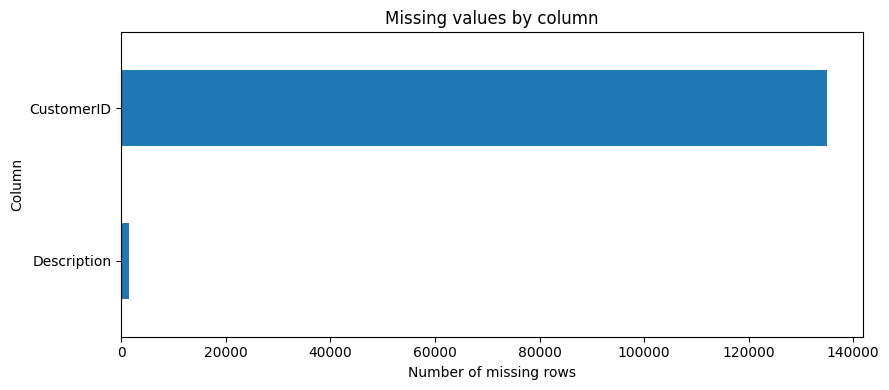

In [4]:
missing_summary = (
    df.isna().sum().rename('missing_rows').to_frame()
    .assign(missing_percent=lambda x: (x['missing_rows'] / len(df) * 100).round(2))
    .sort_values('missing_rows', ascending=False)
)
display(missing_summary)

missing_to_plot = missing_summary[missing_summary['missing_rows'] > 0]
if not missing_to_plot.empty:
    ax = missing_to_plot['missing_rows'].sort_values().plot(kind='barh', figsize=(9, 4))
    ax.set_title('Missing values by column')
    ax.set_xlabel('Number of missing rows')
    ax.set_ylabel('Column')
    plt.tight_layout()
    plt.show()
else:
    print('No missing values found.')

## 5. Exact duplicate investigation

An exact duplicate is defined here as a repeated row across the original transaction columns. Duplicate-looking product lines can occur in transaction systems, so we investigate and flag excess repeated rows rather than deleting them from the raw dataset. The existing pipeline keeps the first occurrence for its provisional positive-sales calculation and flags subsequent exact matches.

In [5]:
duplicate_mask = df.duplicated(keep='first')
duplicate_count = int(duplicate_mask.sum())
print(f'Excess exact duplicate rows: {duplicate_count:,}')
print(f'Rows belonging to duplicate groups (including first occurrence): {int(df.duplicated(keep=False).sum()):,}')

display(df.loc[df.duplicated(keep=False)].sort_values(list(df.columns)).head(12))

Excess exact duplicate rows: 5,268
Rows belonging to duplicate groups (including first occurrence): 10,147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


## 6. Investigate quantities and prices

Negative quantities can indicate returns or other reversals. Zero prices may represent samples, promotional lines, incomplete records, or other special cases. Negative prices may be accounting adjustments. These cases should be inspected and documented rather than assumed to be ordinary sales.

,check,row_count
0,Negative quantity rows,10624
1,Zero quantity rows,0
2,Negative UnitPrice rows,2
3,Zero UnitPrice rows,2515


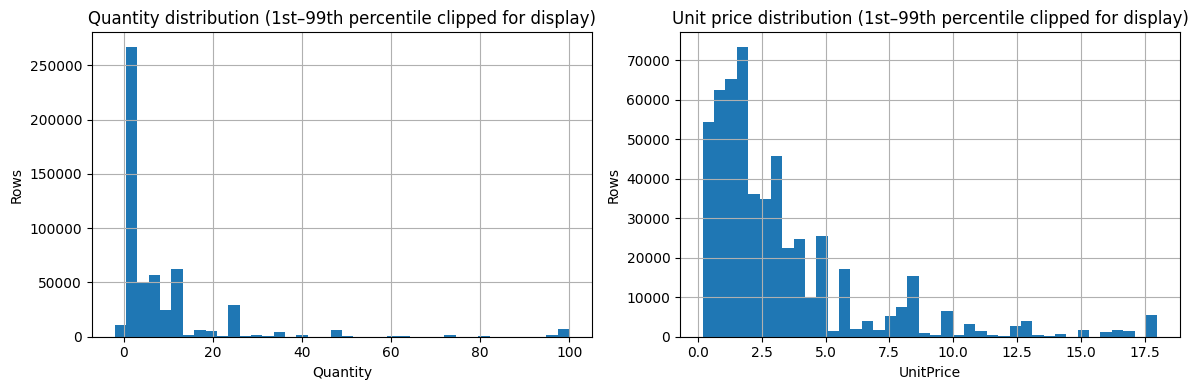

In [6]:
quantity_price_summary = pd.DataFrame({
    'check': [
        'Negative quantity rows', 'Zero quantity rows',
        'Negative UnitPrice rows', 'Zero UnitPrice rows'
    ],
    'row_count': [
        int((df['Quantity'] < 0).sum()),
        int((df['Quantity'] == 0).sum()),
        int((df['UnitPrice'] < 0).sum()),
        int((df['UnitPrice'] == 0).sum()),
    ]
})
display(quantity_price_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['Quantity'].clip(lower=df['Quantity'].quantile(0.01), upper=df['Quantity'].quantile(0.99)).hist(bins=40, ax=axes[0])
axes[0].set_title('Quantity distribution (1st–99th percentile clipped for display)')
axes[0].set_xlabel('Quantity')
axes[0].set_ylabel('Rows')
df['UnitPrice'].clip(lower=df['UnitPrice'].quantile(0.01), upper=df['UnitPrice'].quantile(0.99)).hist(bins=40, ax=axes[1])
axes[1].set_title('Unit price distribution (1st–99th percentile clipped for display)')
axes[1].set_xlabel('UnitPrice')
axes[1].set_ylabel('Rows')
plt.tight_layout()
plt.show()

In [7]:
negative_quantity_examples = df.loc[df['Quantity'] < 0].head(10)
zero_price_examples = df.loc[df['UnitPrice'] == 0].head(10)
negative_price_examples = df.loc[df['UnitPrice'] < 0]

print('Examples with negative quantities')
display(negative_quantity_examples)
print('Examples with zero prices')
display(zero_price_examples)
print('All rows with negative prices')
display(negative_price_examples)

Examples with negative quantities


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Examples with zero prices


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


All rows with negative prices


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


## 7. Cancellation invoice investigation

In this project, invoice identifiers beginning with `C` are flagged as cancellation invoices. This is a classification rule used by the existing pipeline; it does not mean all negative-quantity rows are cancellations. These categories overlap, so their counts must not be added together as if they represented separate rows.

In [8]:
invoice_text = df['InvoiceNo'].astype('string').str.strip()
cancellation_mask = invoice_text.str.startswith('C', na=False)
print(f'Rows with invoice number starting with C: {int(cancellation_mask.sum()):,}')
print(f'Distinct cancellation invoice IDs: {df.loc[cancellation_mask, "InvoiceNo"].nunique():,}')
print(f'Rows with negative quantity: {int((df["Quantity"] < 0).sum()):,}')
print(f'Rows satisfying both conditions: {int((cancellation_mask & (df["Quantity"] < 0)).sum()):,}')

display(df.loc[cancellation_mask, ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']].head(12))

Rows with invoice number starting with C: 9,288
Distinct cancellation invoice IDs: 3,836
Rows with negative quantity: 10,624
Rows satisfying both conditions: 9,288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


## 8. Data quality summary

The values below are expected to match the profile generated by the current project pipeline. If the source dataset changes, revisit these checks instead of blindly updating expected values.

In [9]:
quality_summary = pd.DataFrame([
    ('Source rows', len(df)),
    ('Columns', df.shape[1]),
    ('Missing Description', int(df['Description'].isna().sum())),
    ('Missing CustomerID', int(df['CustomerID'].isna().sum())),
    ('Excess exact duplicate rows', int(df.duplicated(keep='first').sum())),
    ('Distinct invoices', int(df['InvoiceNo'].nunique())),
    ('Distinct products / StockCode', int(df['StockCode'].nunique())),
    ('Distinct non-null CustomerID', int(df['CustomerID'].nunique())),
    ('Distinct countries', int(df['Country'].nunique())),
    ('Negative quantity rows', int((df['Quantity'] < 0).sum())),
    ('Zero price rows', int((df['UnitPrice'] == 0).sum())),
    ('Negative price rows', int((df['UnitPrice'] < 0).sum())),
    ('Cancellation invoice rows', int(cancellation_mask.sum())),
], columns=['Metric', 'Value'])
display(quality_summary)

,Metric,Value
0,Source rows,541909
1,Columns,8
2,Missing Description,1454
3,Missing CustomerID,135080
4,Excess exact duplicate rows,5268
5,Distinct invoices,25900
6,Distinct products / StockCode,4070
7,Distinct non-null CustomerID,4372
8,Distinct countries,38
9,Negative quantity rows,10624


## 9. Document preprocessing decisions

| Issue | Current treatment | Reason / caveat |
|---|---|---|
| Missing CustomerID | Flag and preserve | Row may remain useful for product or country analysis, but not customer attribution. |
| Missing Description | Flag and preserve | Do not infer product descriptions without a defensible source. |
| Exact duplicate rows | Flag excess repeats; preserve source | Prevents silent deletion and allows the provisional measure to avoid counting flagged repeats. Business review may still be needed. |
| Invoice number starts with C | Flag cancellation invoice | Cancellation flag is not identical to negative quantity. |
| Negative Quantity | Flag and preserve | May represent a return or reversal; business metric treatment must be explicit. |
| Zero UnitPrice | Flag and preserve | Could be a sample, promotional line, or other special case. |
| Negative UnitPrice | Flag and preserve | May represent an accounting adjustment rather than product sales. |
| Positive sales eligibility | Quantity > 0, UnitPrice > 0, not cancellation, not excess exact duplicate | This is a provisional analysis rule, not a final accounting definition. |

**Do not describe this process as deleting or fully cleaning every questionable record.** The pipeline classifies records and creates a provisional positive-sales measure while preserving the source rows.

## 10. Validate the existing classified output

This section reads the CSV produced by `src/cleaning.py`. It does not regenerate or overwrite the output. The expected counts below come from the validated run already completed for this project.

In [10]:
if not CLASSIFIED_FILE.exists():
    raise FileNotFoundError(
        f'Classified output not found: {CLASSIFIED_FILE}. '
        'Run `python src/cleaning.py` from the project root first.'
    )

classified = pd.read_csv(CLASSIFIED_FILE, low_memory=False)

required_flags = [
    'IsExcessExactDuplicate', 'IsCancellationInvoice',
    'EligiblePositiveSales', 'PositiveSalesValue'
]
missing_flags = [col for col in required_flags if col not in classified.columns]
if missing_flags:
    raise ValueError(f'Classified CSV is missing expected columns: {missing_flags}')

checks = {
    'Source and classified row counts match': len(df) == len(classified),
    'Excess duplicate count matches expected result': int(classified['IsExcessExactDuplicate'].sum()) == 5268,
    'Cancellation row count matches expected result': int(classified['IsCancellationInvoice'].sum()) == 9288,
    'Positive-sales values are never negative': bool((classified['PositiveSalesValue'] >= 0).all()),
    'Ineligible rows contribute zero positive sales': bool((classified.loc[~classified['EligiblePositiveSales'], 'PositiveSalesValue'] == 0).all()),
    'Flagged excess duplicates contribute zero positive sales': bool((classified.loc[classified['IsExcessExactDuplicate'], 'PositiveSalesValue'] == 0).all()),
}

for check_name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {check_name}")

validation_summary = pd.DataFrame([
    ('Raw source rows', len(df)),
    ('Classified output rows', len(classified)),
    ('Eligible positive-sales rows', int(classified['EligiblePositiveSales'].sum())),
    ('Provisional positive-sales value', round(classified['PositiveSalesValue'].sum(), 2)),
], columns=['Metric', 'Value'])
display(validation_summary)

if not all(checks.values()):
    raise AssertionError('One or more pipeline validation checks failed. Investigate before continuing.')

print('All notebook validation checks passed.')

PASS: Source and classified row counts match
PASS: Excess duplicate count matches expected result
PASS: Cancellation row count matches expected result
PASS: Positive-sales values are never negative
PASS: Ineligible rows contribute zero positive sales
PASS: Flagged excess duplicates contribute zero positive sales


,Metric,Value
0,Raw source rows,541909.0
1,Classified output rows,541909.0
2,Eligible positive-sales rows,524878.0
3,Provisional positive-sales value,10642110.8


All notebook validation checks passed.


## 11. Customer and country coverage

These views help explain the limitations of customer-level analysis. Customer-level metrics can only use rows with an identifiable customer unless a documented attribution strategy is introduced. Country distribution is heavily concentrated in the United Kingdom, so an overall result may largely reflect that market.

,category,rows,percent
0,CustomerID present,406829,75.07
1,CustomerID missing,135080,24.93


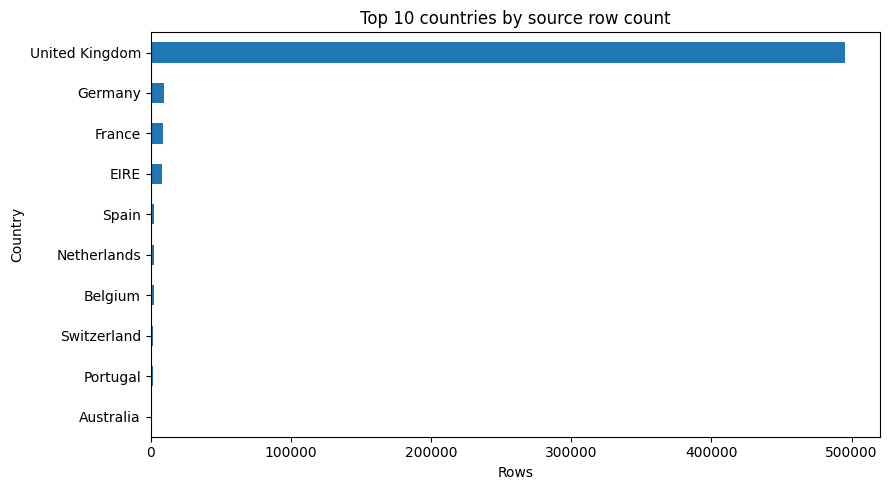

,Country,Rows
0,United Kingdom,495478
1,Germany,9495
2,France,8557
3,EIRE,8196
4,Spain,2533
5,Netherlands,2371
6,Belgium,2069
7,Switzerland,2002
8,Portugal,1519
9,Australia,1259


In [11]:
customer_coverage = pd.DataFrame({
    'category': ['CustomerID present', 'CustomerID missing'],
    'rows': [int(df['CustomerID'].notna().sum()), int(df['CustomerID'].isna().sum())]
})
customer_coverage['percent'] = (customer_coverage['rows'] / len(df) * 100).round(2)
display(customer_coverage)

top_countries = df['Country'].value_counts().head(10).sort_values()
ax = top_countries.plot(kind='barh', figsize=(9, 5))
ax.set_title('Top 10 countries by source row count')
ax.set_xlabel('Rows')
ax.set_ylabel('Country')
plt.tight_layout()
plt.show()

display(df['Country'].value_counts().head(10).rename_axis('Country').reset_index(name='Rows'))

## 12. Conclusions and limitations

### What we learned
- The dataset contains transaction-level records with meaningful missingness and several types of unusual transactions.
- Missing customer IDs limit customer-level attribution for a substantial portion of rows.
- Cancellation invoices, negative quantities, zero prices, negative prices, and exact duplicates are overlapping categories and must be handled with explicit rules.
- The existing pipeline preserves the source row count and flags records rather than silently deleting them.
- The notebook's validation checks should pass before the project proceeds to database loading.

### What is not yet established
- The provisional positive-sales value is not final net revenue.
- Returns and cancellations still need a clearly defined treatment for each business metric.
- Accounting adjustments such as negative-price lines require separate interpretation.
- Duplicate flags identify exact repeated rows, but do not independently prove that every repeated row is an erroneous transaction.

### Next step
After the notebook runs successfully from top to bottom, proceed to PostgreSQL loading and then build SQL-based business metrics with their definitions documented.